In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
#Load dataset
data = pd.read_csv("/content/financial_data.csv")
data = data.drop(columns=["Date"])


In [ ]:
#DataNormalization
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)


In [ ]:
#Create Time-Series Sequences

def create_sequences(data, time_steps=10):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i:i+time_steps])
        y.append(data[i+time_steps, 0])  # Predict Revenue (or Financial Health Index)
    return np.array(X), np.array(y)

TIME_STEPS = 10
X, y = create_sequences(scaled_data, TIME_STEPS)


In [ ]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)


In [ ]:
# CNN–LSTM Hybrid Model

model = Sequential()

# CNN Layers
model.add(Conv1D(filters=64, kernel_size=3, activation='relu',
                 input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(MaxPooling1D(pool_size=2))

# LSTM Layers
model.add(LSTM(100, return_sequences=False))
model.add(Dropout(0.3))

# Output Layer
model.add(Dense(1))

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 8, 64)          │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100)            │        66,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,125 (262.21 KB)

 Trainable params: 67,125 (262.21 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Model Training

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 208ms/step - loss: 0.1891 - mae: 0.3898 - val_loss: 0.1431 - val_mae: 0.3778
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0270 - mae: 0.1366 - val_loss: 0.0039 - val_mae: 0.0619
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.0111 - mae: 0.0866 - val_loss: 0.0637 - val_mae: 0.2519
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.0272 - mae: 0.1496 - val_loss: 0.0172 - val_mae: 0.1309
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0102 - mae: 0.0876 - val_loss: 0.0024 - val_mae: 0.0490
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0026 - mae: 0.0400 - val_loss: 0.0274 - val_mae: 0.1653
Epoch 7/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0061 - mae: 0.0621 - val_loss: 0.0439 - val_mae: 0.2093
Epoch 8/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0114 - mae: 0.0834 - val_loss: 0.0364 - val_mae: 0.1905
Epoch 9/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0084 - mae: 0.0722 -

In [ ]:
# Model Evaluation

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step
Mean Squared Error: 0.0008806772915079714
Mean Absolute Error: 0.022230645883059726


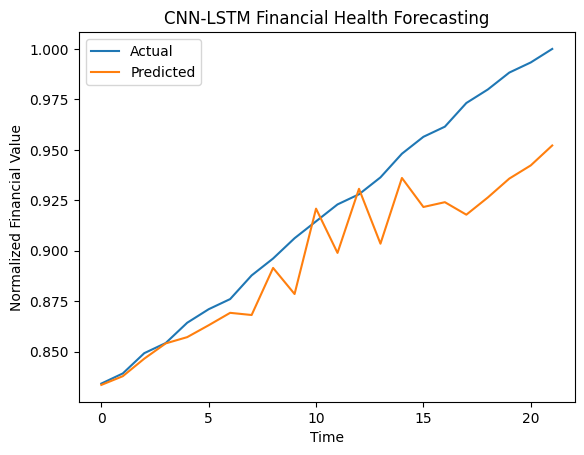

In [ ]:
# Visualization

plt.figure()
plt.plot(y_test, label="Actual")
plt.plot(y_pred, label="Predicted")
plt.title("CNN-LSTM Financial Health Forecasting")
plt.xlabel("Time")
plt.ylabel("Normalized Financial Value")
plt.legend()
plt.show()


In [ ]:
# Save model

model.save("cnn_lstm_financial_health_model.h5")


2nd One !

In [ ]:
#DATA PREPROCESSING

import pandas as pd
from sklearn.preprocessing import MinMaxScaler

df = pd.read_csv("/content/financial_health_project_data.csv")

# Financial Health Index
df["FHI"] = (
    0.3 * df["Revenue"] +
    0.25 * df["Profit"] +
    0.25 * df["CashFlow"] -
    0.2 * df["Liabilities"]
)

features = ["Revenue", "Profit", "Assets", "Liabilities", "CashFlow", "FHI"]

scaler = MinMaxScaler()
df[features] = scaler.fit_transform(df[features])

df.to_csv("/content/financial_health_project_data.csv", index=False)


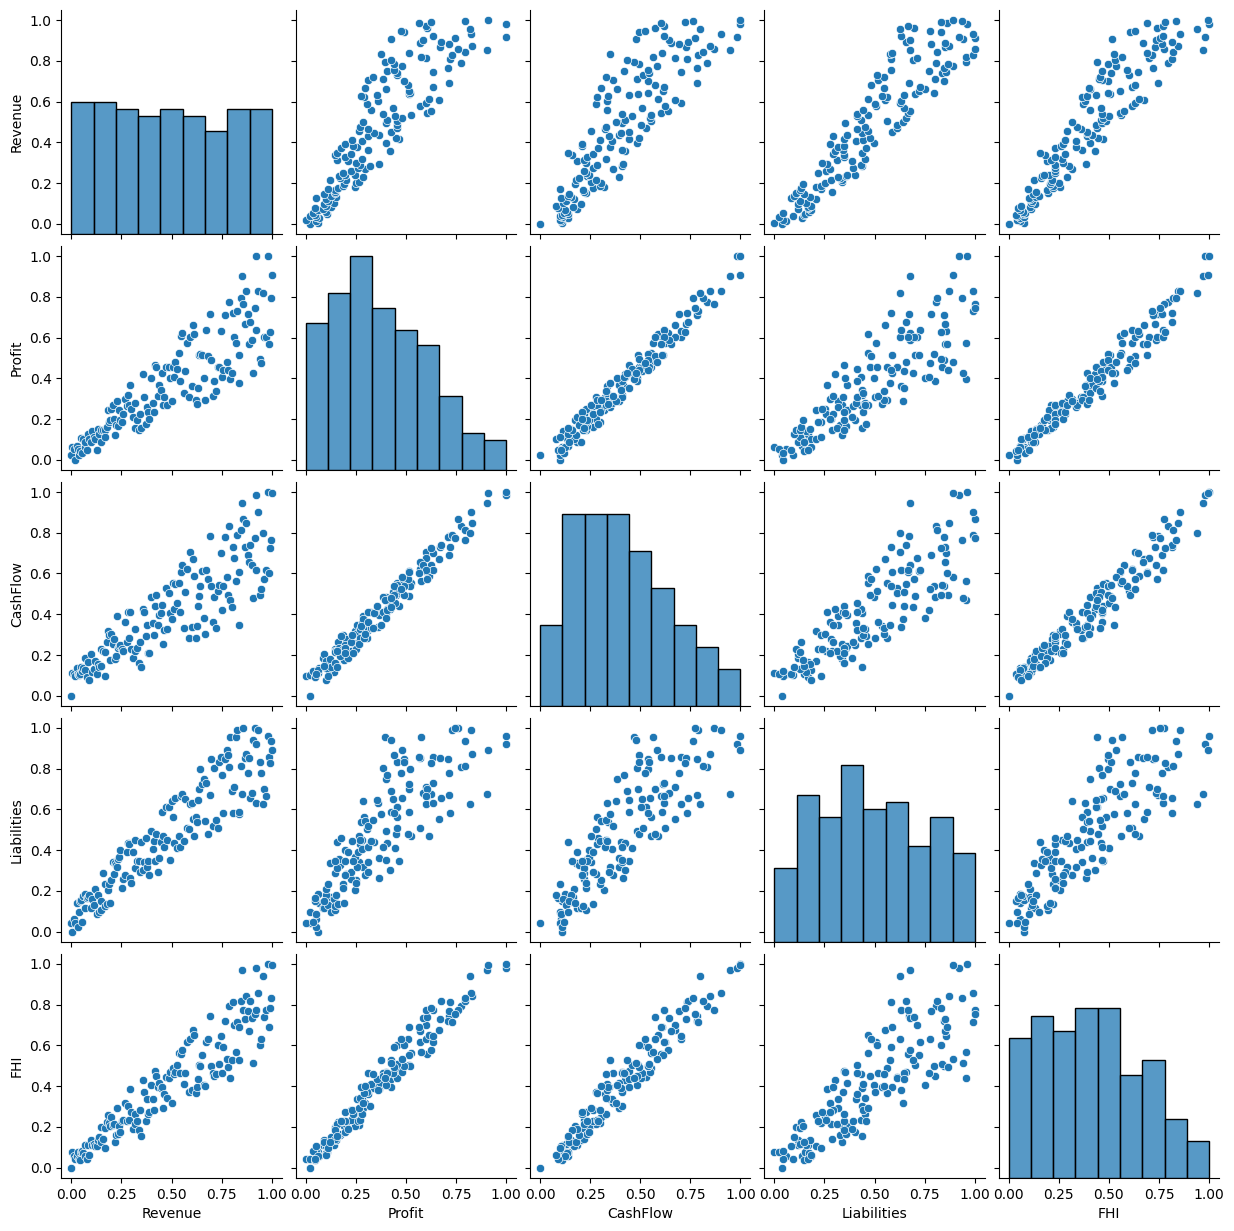

In [ ]:
# EXPLORATORY DATA ANALYSIS

import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(df[["Revenue","Profit","CashFlow","Liabilities","FHI"]])
plt.show()


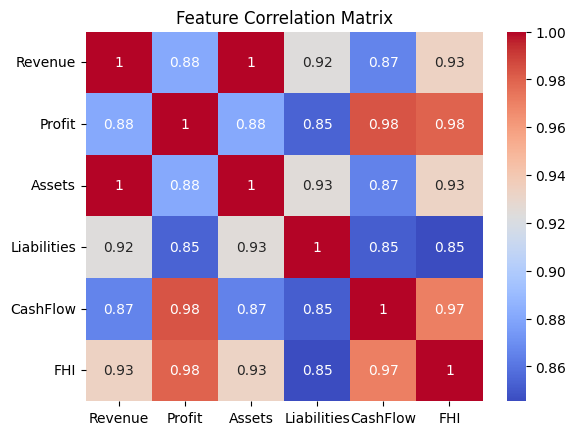

In [ ]:
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Matrix")
plt.show()


In [ ]:
# ADVANCED CNN–LSTM MODEL

import numpy as np

def create_sequences(data, seq_len=12):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i:i+seq_len, :-1])
        y.append(data[i+seq_len, -1])  # Predict FHI
    return np.array(X), np.array(y)

data = df[features].values
X, y = create_sequences(data)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout, BatchNormalization

model = Sequential()

# CNN Block
model.add(Conv1D(64, 3, activation='relu', input_shape=(X.shape[1], X.shape[2])))
model.add(BatchNormalization())
model.add(MaxPooling1D(2))

model.add(Conv1D(128, 3, activation='relu'))
model.add(MaxPooling1D(2))

# LSTM Block
model.add(LSTM(100, return_sequences=True))
model.add(Dropout(0.3))
model.add(LSTM(50))

# Fully Connected
model.add(Dense(50, activation='relu'))
model.add(Dense(1))

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 10, 64)         │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 10, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 5, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 3, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 1, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 1, 100)         │        91,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1, 100)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        30,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 150,385 (587.44 KB)

 Trainable params: 150,257 (586.94 KB)

 Non-trainable params: 128 (512.00 B)

In [ ]:
# TRAINING STRATEGY

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    EarlyStopping(patience=15, restore_best_weights=True),
    ReduceLROnPlateau(patience=8, factor=0.5)
]

history = model.fit(
    X, y,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=callbacks
)


Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 238ms/step - loss: 0.1422 - mae: 0.3392 - val_loss: 0.5084 - val_mae: 0.7011 - learning_rate: 0.0010
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0635 - mae: 0.2177 - val_loss: 0.3623 - val_mae: 0.5880 - learning_rate: 0.0010
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0178 - mae: 0.1117 - val_loss: 0.2289 - val_mae: 0.4612 - learning_rate: 0.0010
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0257 - mae: 0.1209 - val_loss: 0.2430 - val_mae: 0.4761 - learning_rate: 0.0010
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0114 - mae: 0.0850 - val_loss: 0.2849 - val_mae: 0.5181 - learning_rate: 0.0010
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0112 - mae: 0.0788 - val_loss: 0.2894 - val_mae: 0.5223 - learning_rate: 0.0010
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0112 - mae: 0.0755 - val_loss: 0.2653 - val_mae: 0.4988 - learning_rate: 0.0010
Epoch 8/100
4/4 ━━━

In [ ]:
# EVALUATION

from sklearn.metrics import mean_squared_error, r2_score

pred = model.predict(X)

print("MSE:", mean_squared_error(y, pred))
print("R2 Score:", r2_score(y, pred))


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 175ms/step
MSE: 0.08484298129155793
R2 Score: -0.5364881942217261


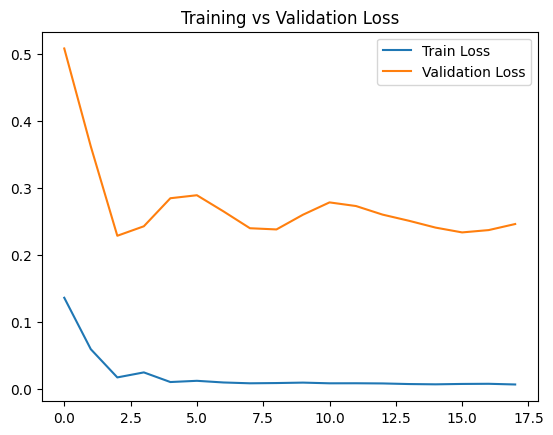

In [ ]:
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Training vs Validation Loss")
plt.show()


In [ ]:
# BUSINESS RISK CLASSIFICATION

df = df.iloc[12:]  # Align lengths
df["Predicted_FHI"] = pred

df["Risk_Level"] = pd.cut(
    df["Predicted_FHI"],
    bins=[0, 0.4, 0.7, 1],
    labels=["High Risk", "Medium Risk", "Low Risk"]
)
